# 03 · Evaluate — Test-set performance and Grad-CAM

**This notebook:**
1. Loads the best checkpoint and decision threshold saved by `02_train.ipynb`
2. Predicts on the held-out **test** split (patients never seen during training or model selection)
3. Reports AUC-ROC, sensitivity, specificity and PPV with 95% confidence intervals
4. Checks where the model struggles (nodule vs mass, PA vs AP view)
5. Shows Grad-CAM heatmaps of where the model is looking
6. Saves figures and metrics to `reports/` for the README

Run it **once**, on the final model. If the model is changed after looking at these numbers, they stop being an honest estimate of performance on new patients.

## 1. Configuration

In [1]:
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repo root
DATA_DIR = ROOT / "data"
IMAGE_DIR = DATA_DIR / "images"
SPLIT_DIR = DATA_DIR / "splits"
CKPT_PATH = ROOT / "checkpoints" / "densenet121_reg_best.pt"   # the run chosen in 02_train, section 11
REPORT_DIR = ROOT / "reports"     # figures and metrics for the README (committed to git)
REPORT_DIR.mkdir(exist_ok=True)

BATCH_SIZE = 64
N_BOOTSTRAP = 1000    # resamples for the 95% confidence intervals
SEED = 42

## 2. Device

In [2]:
import numpy as np
import torch

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


## 3. Load the trained model

`build_model` must build the same architecture as in `02_train.ipynb` so the saved weights fit. It skips the ImageNet download, since the weights come from our checkpoint.

In [3]:
import torch.nn as nn
from torchvision import models


def build_model(name):
    if name == "densenet121":
        model = models.densenet121(weights=None)
        model.classifier = nn.Linear(model.classifier.in_features, 1)
    elif name == "resnet50":
        model = models.resnet50(weights=None)
        model.fc = nn.Linear(model.fc.in_features, 1)
    else:
        raise ValueError(f"Unknown model: {name}")
    return model


ckpt = torch.load(CKPT_PATH, map_location="cpu")
MODEL_NAME, IMG_SIZE, THRESHOLD = ckpt["model_name"], ckpt["img_size"], ckpt["threshold"]

model = build_model(MODEL_NAME)
model.load_state_dict(ckpt["state_dict"])
model = model.to(device).eval()

print(f"{MODEL_NAME} from epoch {ckpt['epoch']} | val AUC {ckpt['val_auc']:.4f} "
      f"| threshold {THRESHOLD:.3f} (chosen for {ckpt['target_sensitivity']:.0%} val sensitivity)")

densenet121 from epoch 6 | val AUC 0.8262 | threshold 0.120 (chosen for 90% val sensitivity)


## 4. Predict on the test set

Same preprocessing as validation in `02_train.ipynb`: resize and normalise, no augmentation.

In [4]:
import pandas as pd
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2 as T

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class ChestXrayDataset(Dataset):
    def __init__(self, df, image_dir, transform):
        self.files = df["Image Index"].tolist()
        self.labels = df["label"].astype("float32").tolist()
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        img = Image.open(self.image_dir / self.files[i]).convert("RGB")
        return self.transform(img), torch.tensor(self.labels[i])


test_df = pd.read_csv(SPLIT_DIR / "test.csv")
print(f"test: {len(test_df)} images | {test_df['Patient ID'].nunique()} patients "
      f"| positive rate {test_df['label'].mean():.1%}")

test_loader = DataLoader(ChestXrayDataset(test_df, IMAGE_DIR, eval_tf), batch_size=BATCH_SIZE, shuffle=False)
probs = []
with torch.no_grad():
    for x, _ in test_loader:
        probs.append(torch.sigmoid(model(x.to(device)).squeeze(1)).cpu())

test_df["prob"] = torch.cat(probs).numpy()
test_df["pred"] = (test_df["prob"] >= THRESHOLD).astype(int)
labels, scores = test_df["label"].to_numpy(), test_df["prob"].to_numpy()

test: 6966 images | 2917 patients | positive rate 25.4%


## 5. Test metrics with 95% confidence intervals

- **AUC-ROC:** how well the model ranks nodule/mass X-rays above normal ones, across all thresholds (0.5 = chance, 1.0 = perfect).
- **Sensitivity:** share of nodule/mass X-rays that get flagged, at the threshold chosen on validation.
- **Specificity:** share of normal X-rays correctly left unflagged.
- **PPV** (precision): share of flagged X-rays that really show a nodule/mass. It depends on the 25% positive rate built into this cohort; where nodules are rarer, as in everyday practice, it would be lower.

The confidence intervals come from a **patient-level bootstrap**: patients, not images, are resampled with replacement, because X-rays of the same patient are not independent.

In [5]:
from sklearn.metrics import roc_auc_score


def metrics(y, p):
    pred = p >= THRESHOLD
    pos, neg = y == 1, y == 0
    return {
        "AUC": roc_auc_score(y, p),
        "Sensitivity": (pred & pos).sum() / pos.sum(),
        "Specificity": (~pred & neg).sum() / neg.sum(),
        "PPV": (pred & pos).sum() / max(pred.sum(), 1),
    }


point = metrics(labels, scores)

rng = np.random.default_rng(SEED)
patient_rows = list(test_df.groupby("Patient ID").indices.values())   # row positions per patient
boot = []
for _ in range(N_BOOTSTRAP):
    picked = rng.integers(0, len(patient_rows), len(patient_rows))
    idx = np.concatenate([patient_rows[k] for k in picked])
    boot.append(metrics(labels[idx], scores[idx]))
boot = pd.DataFrame(boot)

results = pd.DataFrame({
    "value": point,
    "95% CI low": boot.quantile(0.025),
    "95% CI high": boot.quantile(0.975),
})
results.style.format("{:.3f}")

,value,95% CI low,95% CI high
AUC,0.812,0.794,0.827
Sensitivity,0.903,0.881,0.919
Specificity,0.452,0.432,0.472
PPV,0.359,0.332,0.385


Confusion matrix at the chosen threshold:

In [6]:
confusion = pd.crosstab(
    test_df["label"].map({1: "nodule/mass", 0: "no finding"}).rename("actual"),
    test_df["pred"].map({1: "flagged", 0: "not flagged"}).rename("model"),
).reindex(index=["nodule/mass", "no finding"], columns=["flagged", "not flagged"], fill_value=0)
confusion

model,flagged,not flagged
actual,,
nodule/mass,1596,172
no finding,2850,2348


## 6. ROC curve

Each point on the curve is one possible threshold. The dot marks the threshold chosen on validation.

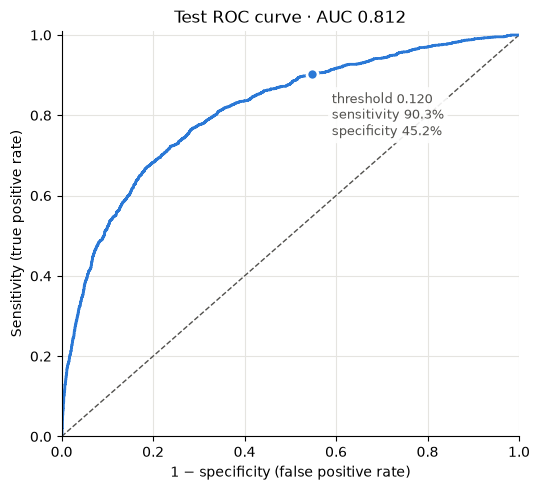

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

LINE_COLOR, MUTED, GRID = "#2a78d6", "#52514e", "#e5e4e0"

fpr, tpr, _ = roc_curve(labels, scores)
op_x, op_y = 1 - point["Specificity"], point["Sensitivity"]

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls="--", lw=1, color=MUTED)                    # chance
ax.plot(fpr, tpr, color=LINE_COLOR, lw=2)
ax.plot(op_x, op_y, "o", ms=8, color=LINE_COLOR, mec="white", mew=2)
ax.annotate(f"threshold {THRESHOLD:.3f}\nsensitivity {op_y:.1%}\nspecificity {1 - op_x:.1%}",
            (op_x, op_y), xytext=(14, -44), textcoords="offset points", fontsize=9, color=MUTED,
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.9))
ax.set(title=f"Test ROC curve · AUC {point['AUC']:.3f}", xlim=(0, 1), ylim=(0, 1.01),
       xlabel="1 − specificity (false positive rate)", ylabel="Sensitivity (true positive rate)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color=GRID, lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig(REPORT_DIR / "roc_test.png", dpi=150)
plt.show()

## 7. Where does the model struggle?

- **Sensitivity by finding type:** a mass is larger than 3 cm and a nodule is 3 cm or smaller, so masses should be easier to catch.
- **Alone vs with other findings:** the negatives are only "No Finding" X-rays, so the model may partly learn "abnormal vs normal" instead of "nodule/mass". If sensitivity is much higher when the nodule/mass comes with other findings (effusion, infiltration, ...), that's a sign of it.
- **AUC by view:** PA X-rays are taken standing in the radiology department; AP X-rays are usually taken at the bedside of sicker patients and tend to be lower quality.

In [8]:
pos_df = test_df[test_df["label"] == 1]
findings = pos_df["Finding Labels"].str.split("|")
has_nodule = findings.apply(lambda f: "Nodule" in f)
has_mass = findings.apply(lambda f: "Mass" in f)
finding_type = np.select([has_nodule & has_mass, has_mass], ["nodule + mass", "mass only"], default="nodule only")
by_type = pos_df.groupby(finding_type)["pred"].agg(images="size", sensitivity="mean")

has_other = findings.apply(lambda f: any(x not in ("Nodule", "Mass") for x in f))
by_other = (pos_df.groupby(np.where(has_other, "with other findings", "nodule/mass alone"))["pred"]
            .agg(images="size", sensitivity="mean"))

rows = []
for view, g in test_df.groupby("View Position"):
    rows.append({"view": view, "images": len(g), "positive rate": g["label"].mean(),
                 "AUC": roc_auc_score(g["label"], g["prob"])})
by_view = pd.DataFrame(rows).set_index("view")

display(by_type.style.format({"sensitivity": "{:.1%}"}))
display(by_other.style.format({"sensitivity": "{:.1%}"}))
display(by_view.style.format({"positive rate": "{:.1%}", "AUC": "{:.3f}"}))

,images,sensitivity
mass only,812,92.6%
nodule + mass,139,97.1%
nodule only,817,86.8%


,images,sensitivity
nodule/mass alone,858,86.8%
with other findings,910,93.5%


,images,positive rate,AUC
view,,,
AP,2514,26.4%,0.773
PA,4452,24.8%,0.829


## 8. Grad-CAM: where is the model looking?

Grad-CAM highlights the regions that pushed the model's nodule/mass score up (red = strongest). It is a sanity check, not proof: heat on the lungs is reassuring, while heat on text markers, tubes or the image border would suggest the model learned a shortcut.

- **Row 1:** the most confident correct detections
- **Row 2:** the nodules/masses the model missed by the widest margin
- **Row 3:** the normal X-rays the model was most wrongly confident about

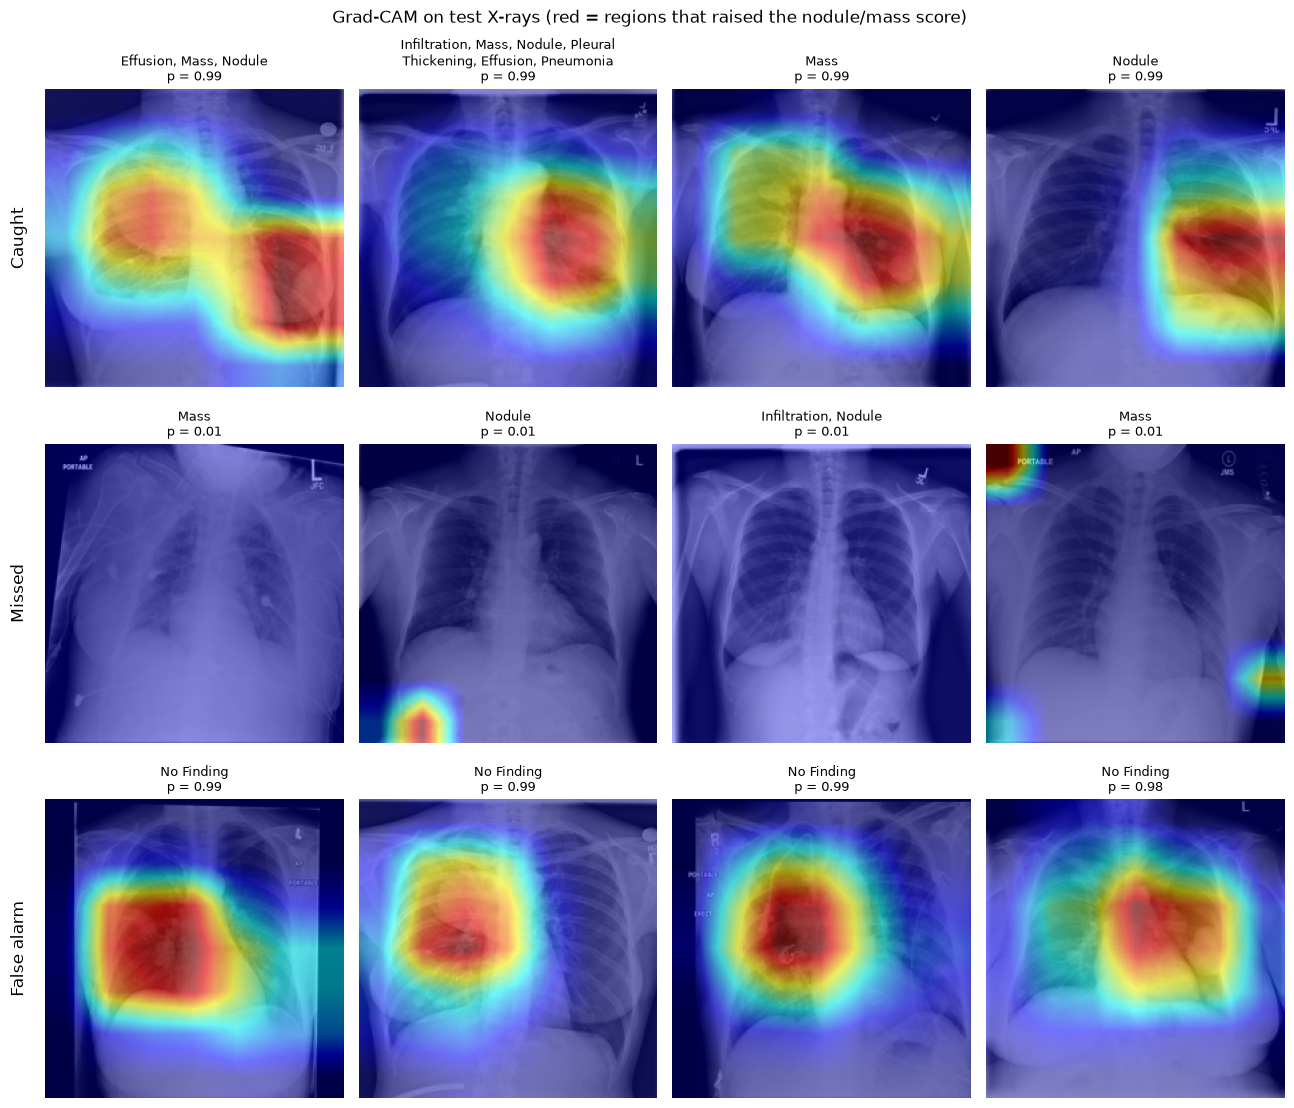

In [9]:
import textwrap

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

target_layer = model.features[-1] if MODEL_NAME == "densenet121" else model.layer4[-1]
cam = GradCAM(model=model, target_layers=[target_layer])

is_pos, flagged = test_df["label"] == 1, test_df["pred"] == 1
examples = {
    "Caught": test_df[is_pos & flagged].nlargest(4, "prob"),
    "Missed": test_df[is_pos & ~flagged].nsmallest(4, "prob"),
    "False alarm": test_df[~is_pos & flagged].nlargest(4, "prob"),
}

fig, axes = plt.subplots(3, 4, figsize=(13, 11.5))
for row_axes, (name, rows) in zip(axes, examples.items()):
    for ax, (_, r) in zip(row_axes, rows.iterrows()):
        img = Image.open(IMAGE_DIR / r["Image Index"]).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        heat = cam(input_tensor=eval_tf(img).unsqueeze(0).to(device), targets=[ClassifierOutputTarget(0)])[0]
        ax.imshow(show_cam_on_image(np.asarray(img, dtype=np.float32) / 255, heat, use_rgb=True))
        labels_text = textwrap.fill(r["Finding Labels"].replace("|", ", ").replace("_", " "), 38)
        ax.set_title(f"{labels_text}\np = {r['prob']:.2f}", fontsize=9)
    for ax in row_axes:
        ax.axis("off")
    row_axes[0].text(-0.06, 0.5, name, transform=row_axes[0].transAxes,
                     rotation=90, va="center", ha="right", fontsize=12)
fig.suptitle("Grad-CAM on test X-rays (red = regions that raised the nodule/mass score)")
plt.tight_layout()
fig.savefig(REPORT_DIR / "gradcam_test.png", dpi=120, bbox_inches="tight")
plt.show()

## 9. Save the results

In [10]:
import json

summary = {
    "model": MODEL_NAME,
    "checkpoint_epoch": ckpt["epoch"],
    "threshold": round(THRESHOLD, 4),
    "test_images": len(test_df),
    "test_patients": int(test_df["Patient ID"].nunique()),
    "metrics": {
        k: {"value": round(float(point[k]), 4),
            "ci95": [round(float(boot[k].quantile(0.025)), 4), round(float(boot[k].quantile(0.975)), 4)]}
        for k in point
    },
}
(REPORT_DIR / "test_metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved to", REPORT_DIR, ":", sorted(p.name for p in REPORT_DIR.iterdir()))

Saved to /Users/TrungVu/code/chest_xray_classifier/reports : ['gradcam_test.png', 'roc_test.png', 'test_metrics.json']


## Summary

- Evaluated the final model once on the held-out test set: patients never seen during training or model selection.
- Reported AUC-ROC, sensitivity, specificity and PPV with patient-level bootstrap 95% confidence intervals.
- Checked performance by finding type, by whether other findings were present, and by X-ray view, and inspected Grad-CAM heatmaps.
- Saved `reports/roc_test.png`, `reports/gradcam_test.png` and `reports/test_metrics.json` for the README.

**Next:** upload the checkpoint to Hugging Face and build the demo Space.